# 02 - Pretraitement d'une image

Objectif : charger une image de Caltech-101, la redimensionner et obtenir ses representations HSV et en niveaux de gris. La taille 256 x 256 est un point de depart a tester.

In [1]:
#%pip install pillow

Image : data\101_ObjectCategories\airplanes\image_0001.jpg
Taille originale : (398, 164)


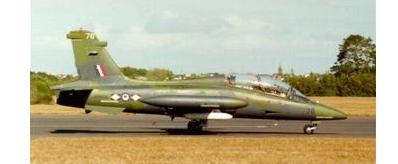

In [2]:
from pathlib import Path
from PIL import Image
from IPython.display import display

chemin = Path('data/101_ObjectCategories/airplanes/image_0001.jpg')
if not chemin.is_file():
    raise FileNotFoundError(f'Image introuvable : {chemin.resolve()}. Ouvrir le notebook depuis le dossier du projet.')

with Image.open(chemin) as fichier:
    originale = fichier.convert('RGB')

print(f'Image : {chemin}')
print(f'Taille originale : {originale.size}')
display(originale)

## Redimensionnement et conversions

Le redimensionnement direct en carre peut deformer les images rectangulaires. On garde ce choix comme reference initiale et on pourra le comparer plus tard avec une methode conservant les proportions. HSV contient teinte (H), saturation (S) et valeur (V) ; la version grise servira a etudier la texture.

Image redimensionnee (RGB) : (256, 256)


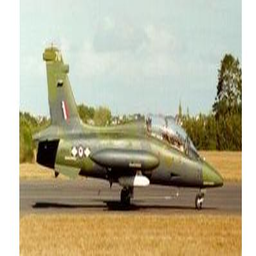

Image en niveaux de gris :


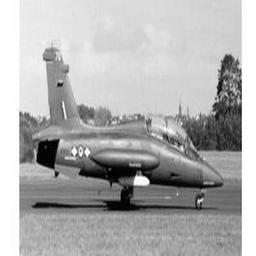

Image HSV reconvertie en RGB pour affichage :


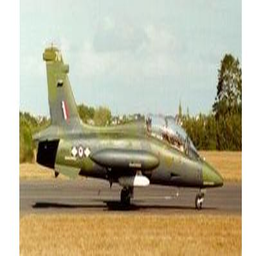

Teinte (H)


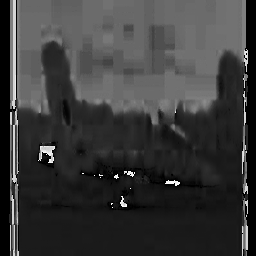

Saturation (S)


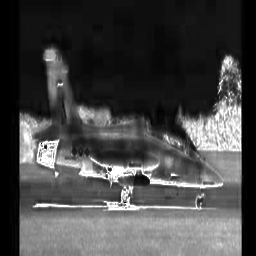

Valeur (V)


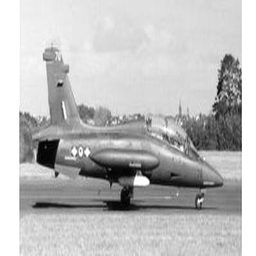

In [3]:
redimensionnee = originale.resize((256, 256), Image.Resampling.LANCZOS)
hsv = redimensionnee.convert('HSV')
grise = redimensionnee.convert('L')
assert redimensionnee.size == hsv.size == grise.size == (256, 256)
assert hsv.mode == 'HSV' and grise.mode == 'L'

print('Image redimensionnee (RGB) :', redimensionnee.size)
display(redimensionnee)
print('Image en niveaux de gris :')
display(grise)

print('Image HSV reconvertie en RGB pour affichage :')
display(hsv.convert('RGB'))
for nom, canal in zip(('Teinte (H)', 'Saturation (S)', 'Valeur (V)'), hsv.split()):
    print(nom)
    display(canal)

## Observation

La reconversion HSV vers RGB permet seulement de visualiser les couleurs : elle ne visualise pas directement les trois composantes. Les images H, S et V sont affichees separement en niveaux de gris. Aucune signature ni recherche n'est encore calculee.